In [1]:
!git clone https://github.com/harsh1243/multi-objective-tetris-rl.git
%cd multi-objective-tetris-rl
!ls

Cloning into 'multi-objective-tetris-rl'...
remote: Enumerating objects: 81, done.
remote: Counting objects: 100% (81/81), done.
remote: Compressing objects: 100% (74/74), done.
remote: Total 81 (delta 31), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (81/81), 65.76 KiB | 1.49 MiB/s, done.
Resolving deltas: 100% (31/31), done.
/kaggle/working/multi-objective-tetris-rl
evaluate.py  plot.py		     reward.py		 tetris_viz.py
features.py  ppo.py		     run_experiments.py
models	     README.md		     tetris_demo.py
network.py   requirements-train.txt  tetris_env.py


In [2]:
import torch
print("GPU available:", torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")
!python reward.py
!python tetris_env.py
!python ppo.py --self-test

GPU available: True
Tesla T4
reward.py: all self-tests passed
legal actions on empty board: {'I': 17, 'O': 9, 'T': 34, 'S': 17, 'Z': 17, 'J': 34, 'L': 34}
line clear test ok, info: {'piece': 'I', 'landing_row': 19, 'lines_cleared': 1}
afterstate features ok
step() matches the afterstate preview
determinism ok
random agent: mean length 25.4 pieces, 860 placements/sec
tetris_env.py: all self-tests passed
GAE ok
checkpoint iterations: [1, 10, 50, 100, 200, 300, 400, 500]
it     1/3 steps        64 | lines     0.0 pieces    20.0 | pol -0.000 val 262.224 ent 3.04 kl 0.0000 clip 0.00 ev 0.01 | 128 steps/s
it     2/3 steps       128 | lines     0.0 pieces    20.0 | pol -0.000 val 217.915 ent 2.98 kl 0.0000 clip 0.00 ev -0.04 | 177 steps/s
it     3/3 steps       192 | lines     0.0 pieces    20.0 | pol -0.000 val 323.473 ent 2.93 kl 0.0000 clip 0.00 ev -0.05 | 203 steps/s
done. checkpoints in /tmp/tmpa23j7whg/t/checkpoints
resumed from /tmp/tmpa23j7whg/t/checkpoints/final.pt at iteration 3
it 

In [3]:
!python ppo.py --run-name speed_cpu --total-steps 20480 --device cpu | tail -1
!python ppo.py --run-name speed_gpu --total-steps 20480 --device cuda | tail -1
!rm -rf runs/speed_cpu runs/speed_gpu

done. checkpoints in runs/speed_cpu/checkpoints
done. checkpoints in runs/speed_gpu/checkpoints


In [3]:
!python run_experiments.py --settings multi --seeds 0 --total-steps 2000000 --device cuda


1 run(s) to do, 1 at a time, 2,000,000 placements each

start  multi_s0 (new)  log: runs/multi_s0/train.log
--- progress ---
multi_s0: 
--- progress ---
multi_s0: it    30/977 steps     61440 | lines   170.8 pieces   451.0 | pol -0.002 val 16.888 ent 0.77 kl 0.0004 clip 0.00 ev 0.40 | 605 steps/s
--- progress ---
multi_s0: it    60/977 steps    122880 | lines   194.0 pieces   500.0 | pol -0.002 val 4.523 ent 0.58 kl 0.0007 clip 0.01 ev 0.61 | 595 steps/s
--- progress ---
multi_s0: it   100/977 steps    204800 | lines   188.5 pieces   491.8 | pol -0.000 val 33.416 ent 0.44 kl 0.0003 clip 0.00 ev 0.15 | 595 steps/s
--- progress ---
multi_s0: it   130/977 steps    266240 | lines   197.0 pieces   500.0 | pol -0.002 val 1.384 ent 0.38 kl 0.0013 clip 0.02 ev 0.90 | 597 steps/s
--- progress ---
multi_s0: it   170/977 steps    348160 | lines   167.0 pieces   432.6 | pol -0.001 val 19.402 ent 0.33 kl 0.0005 clip 0.00 ev 0.42 | 600 steps/s
--- progress ---
multi_s0: it   200/977 steps    409600

saved figures/fig1_lines_vs_steps.png
saved figures/fig2_pieces_vs_steps.png
saved figures/fig6_entropy.png
saved figures/fig5_board_quality.png
saved figures/fig7_losses.png
no results/summary.csv yet: run evaluate.py for figures 3 and 4
no results/sweep.csv yet: run 'python evaluate.py --sweep' for figure 8


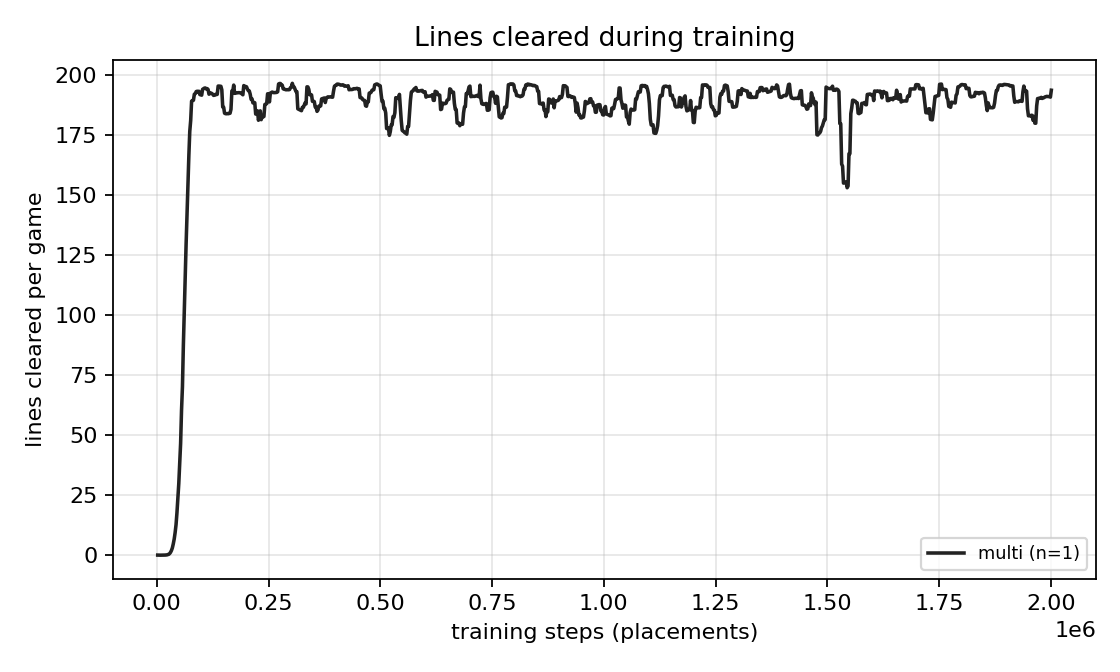

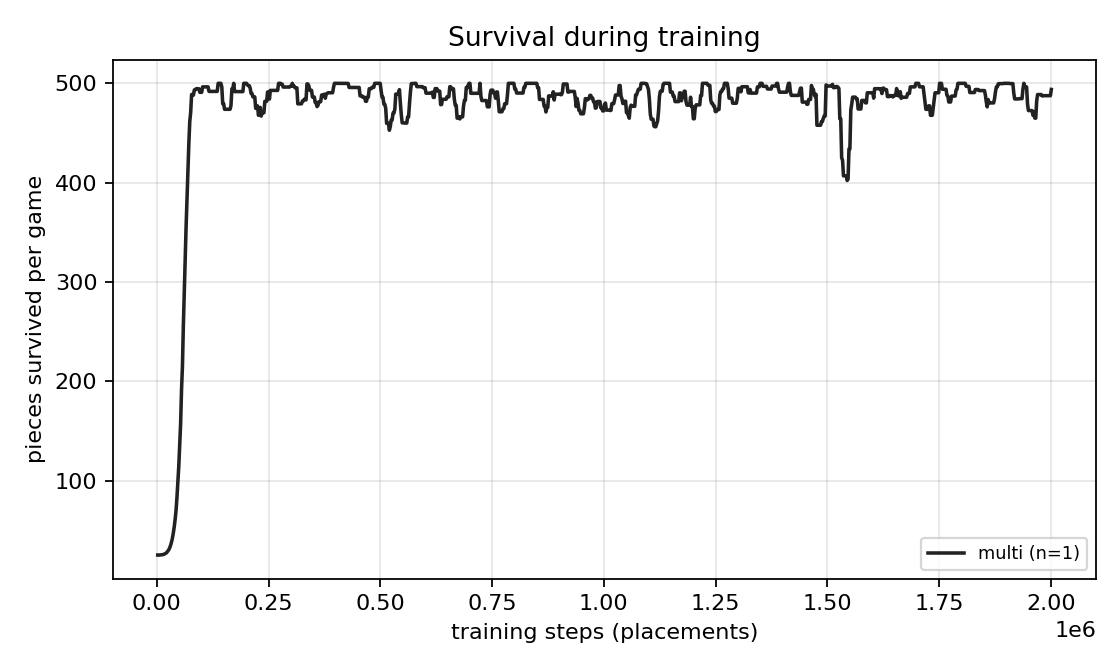

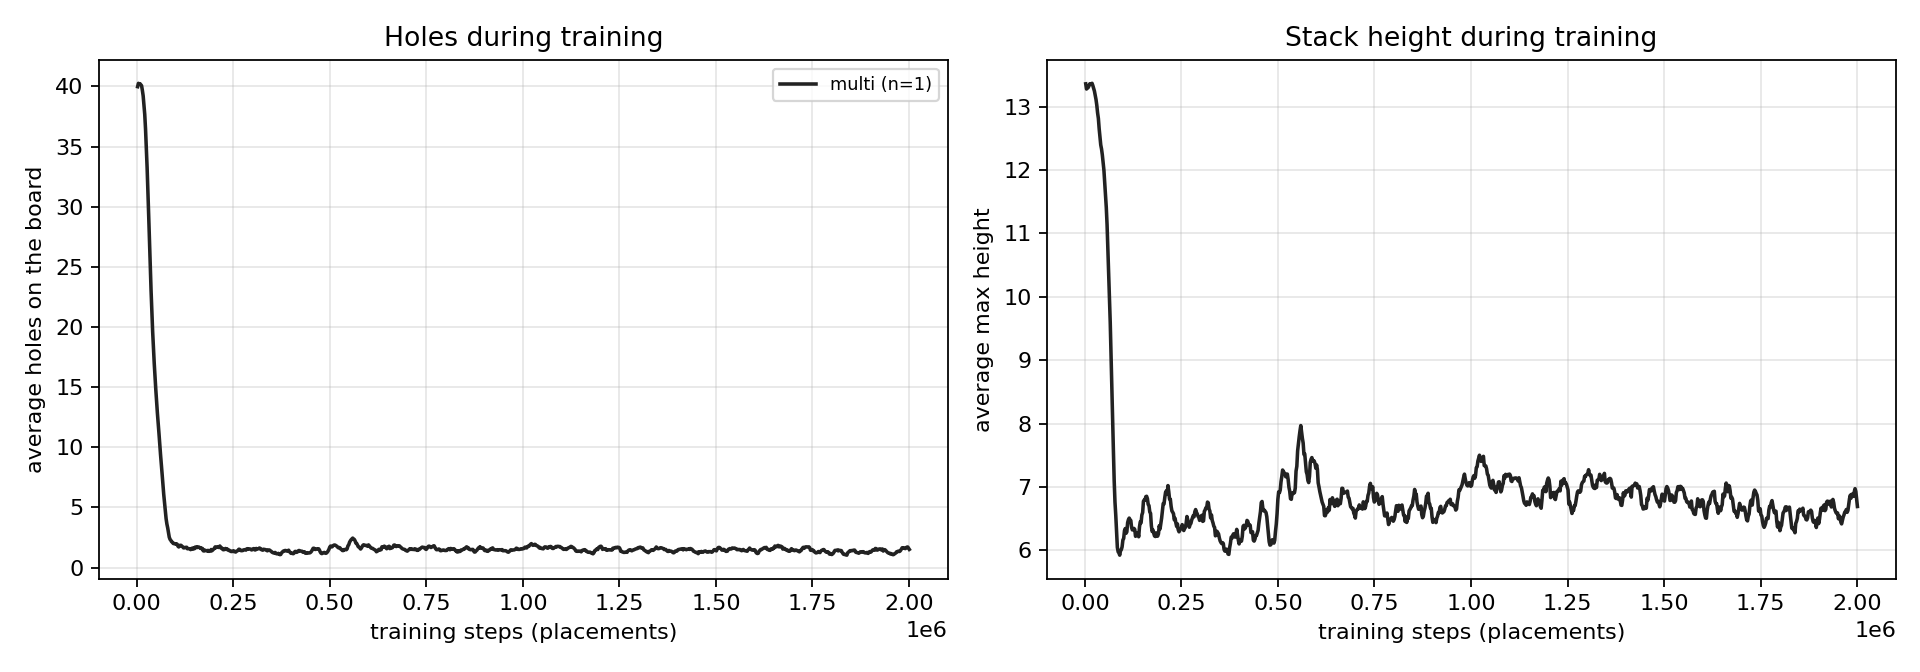

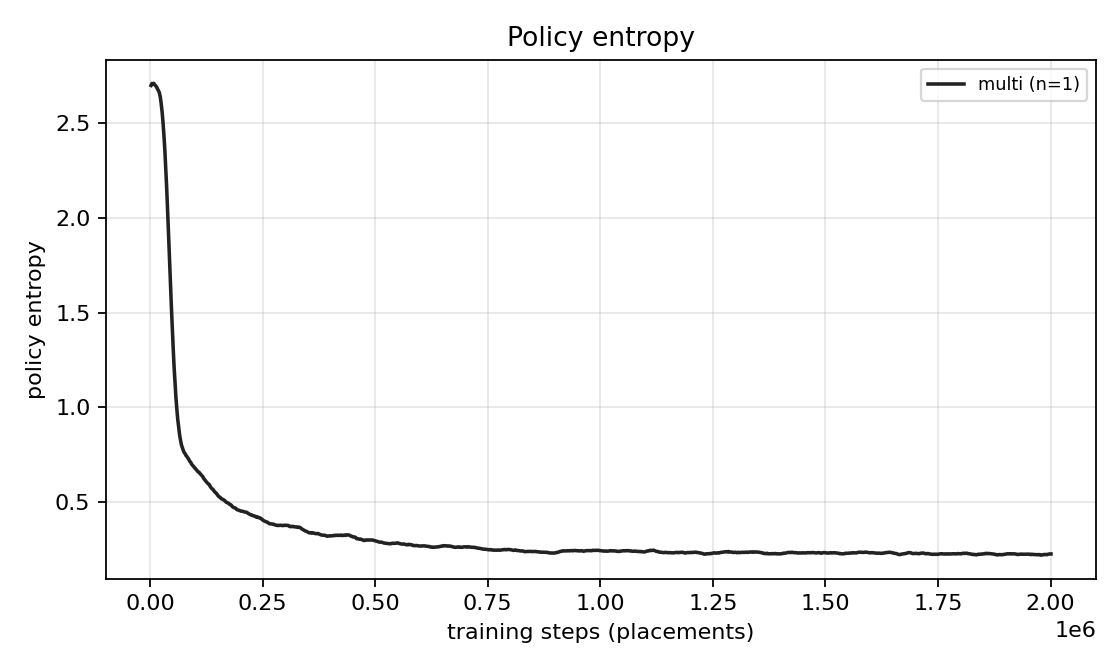

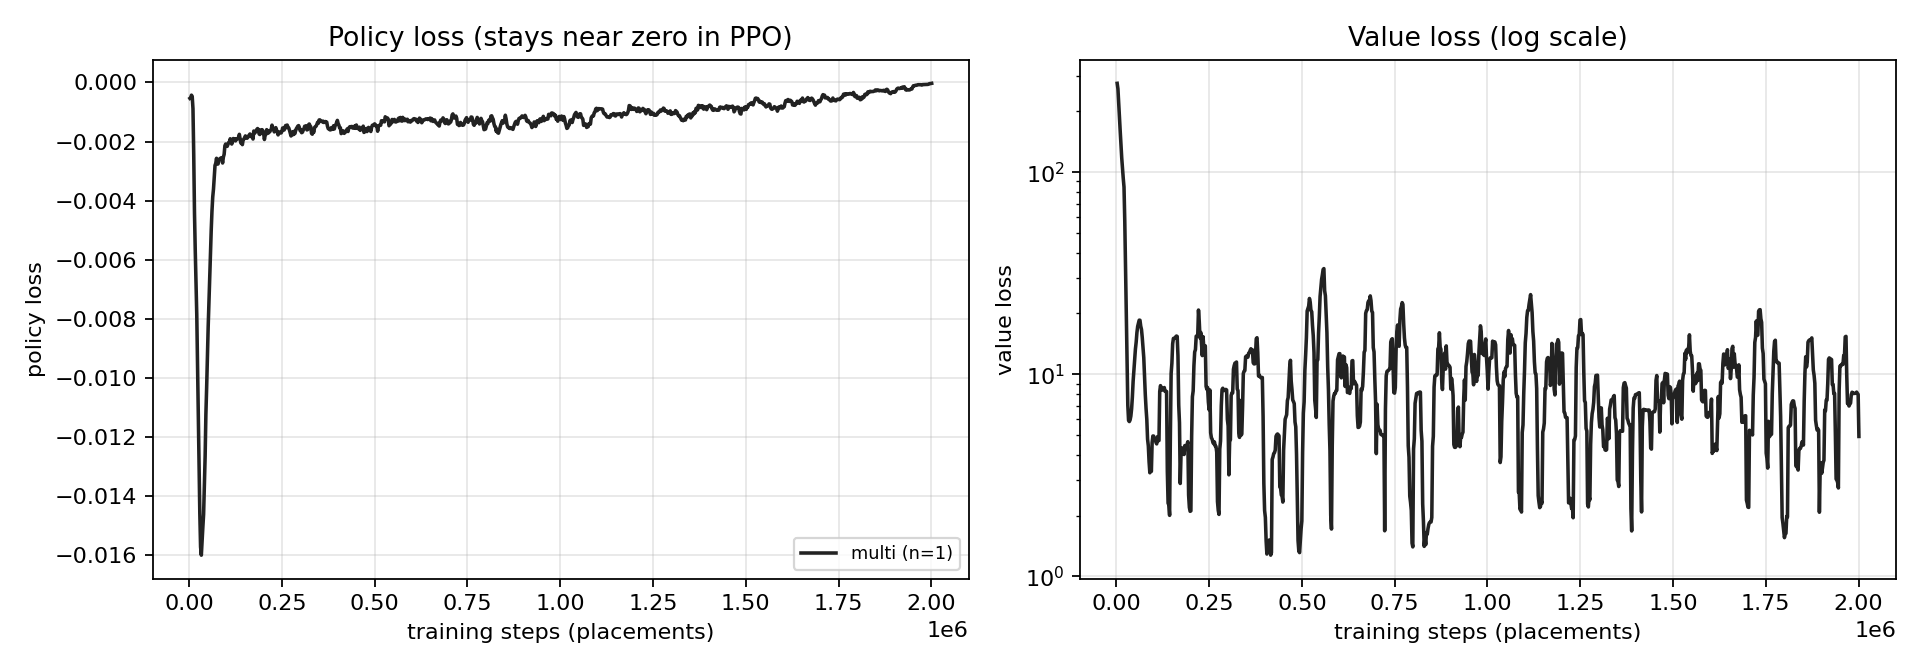

In [5]:
!rm -rf runs/speed_gpu runs/speed_cpu
!python plot.py

from IPython.display import Image, display
for f in ["fig1_lines_vs_steps", "fig2_pieces_vs_steps", "fig5_board_quality", "fig6_entropy", "fig7_losses"]:
    display(Image(f"figures/{f}.png"))

In [7]:
# 1) Check training finished (final.pt must exist)
!ls -lh runs/multi_s0/checkpoints/final.pt

# 2) Copy the files the demo needs into models/
!mkdir -p models
!cp runs/multi_s0/checkpoints/final.pt models/multi_s0_final.pt
!cp runs/multi_s0/config.json models/multi_s0_config.json

# 3) Zip them into one file
!zip tetris_model.zip models/multi_s0_final.pt models/multi_s0_config.json
!ls -lh tetris_model.zip

# 4) Download link
from IPython.display import FileLink
FileLink("tetris_model.zip")

-rw-r--r-- 1 root root 1.6M Oct 29 15:12 runs/multi_s0/checkpoints/final.pt
updating: models/multi_s0_final.pt (deflated 28%)
updating: models/multi_s0_config.json (deflated 50%)
-rw-r--r-- 1 root root 1.2M Oct 29 15:12 tetris_model.zip


/kaggle/working/multi-objective-tetris-rl/tetris_model.zip

In [8]:
!cp tetris_model.zip /kaggle/working/
!ls -lh /kaggle/working/*.zip

-rw-r--r-- 1 root root 1.2M Oct 29 15:16 /kaggle/working/tetris_model.zip
